In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("transformed_retail_sales.csv", parse_dates=["Order_Date"])
# Year, Month and Quarter have a few missing values, so keep them as integers
for col in ["Year", "Month", "Quarter"]:
    df[col] = df[col].astype("Int64")

print(df.shape)  df.head()


(2965, 29)


,Order_ID,Order_Date,Customer_ID,Customer_Name,Segment,Product_Name,Category,Sub_Category,Region,City,...,Year,Month,Month_Name,Quarter,Profit_Status,Discount_Amount,Gross_Order_Value,Customer_Segment,Discount_Level,Product_Performance
0,ORD-100592,2025-12-16,CUST-1016,Isha Kapoor,Consumer,Keyboard,Technology,Accessories,East,Ranchi,...,2025,12,December,4,Low Profit,1355.96,9039.70,High Value,Low Discount,Average Performer
1,ORD-101987,2025-11-19,CUST-1008,Pooja Verma,Consumer,Bookshelf,Furniture,Bookcases,South,Chennai,...,2025,11,November,4,Low Profit,840.84,16816.82,Medium Value,Low Discount,Top Performer
2,ORD-100483,2024-05-01,CUST-1018,Kavya Desai,Consumer,Business Phone,Technology,Phones,East,Kolkata,...,2024,5,May,2,Loss,9533.14,95331.40,Low Value,Low Discount,Average Performer
3,ORD-101340,2025-12-23,CUST-1002,Priya Patil,Consumer,Conference Table,Furniture,Tables,East,Kolkata,...,2025,12,December,4,High Profit,4480.49,22402.47,Low Value,High Discount,Average Performer
4,ORD-101362,2025-09-10,CUST-1011,Karan Mehta,Corporate,Desk Lamp,Furniture,Furnishings,North,Jaipur,...,2025,9,September,3,High Profit,0.00,1697.18,Medium Value,No Discount,Under Performer


In [ ]:
total_sales=df["Sales"].sum()
print("Total_Sales:",total_sales)

Total_Sales: 120457049.43


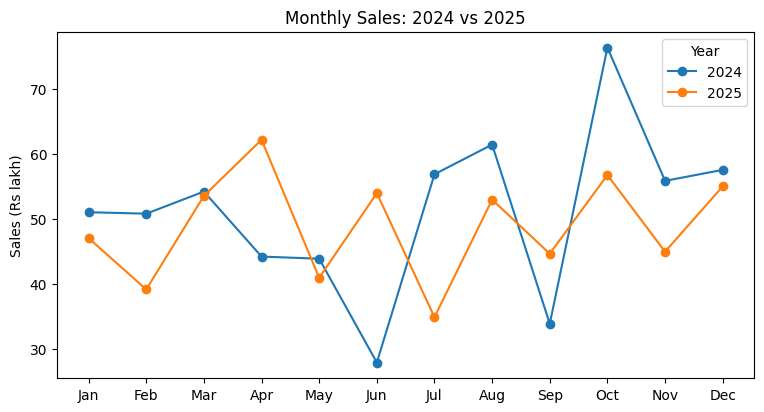

Year,2024,2025
Jan,51.0,47.0
Feb,50.8,39.1
Mar,54.2,53.5
Apr,44.2,62.2
May,43.9,40.9
Jun,27.9,54.0
Jul,56.9,34.9
Aug,61.4,53.0
Sep,33.9,44.6
Oct,76.3,56.7


In [3]:
# Year and Month have a few missing values,so keep them as int
df["Year"] = df["Year"].astype("Int64")
df["Month"] = df["Month"].astype("Int64")

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

monthly = df.pivot_table(index="Month", columns="Year", values="Sales", aggfunc="sum") / 1e5
monthly.index = [month_names[m - 1] for m in monthly.index]

monthly.plot(marker="o", figsize=(9, 4.5))
plt.title("Monthly Sales: 2024 vs 2025")
plt.ylabel("Sales (Rs lakh)")
plt.xlabel("")
plt.xticks(range(12), month_names)
plt.show()

monthly.round(1)

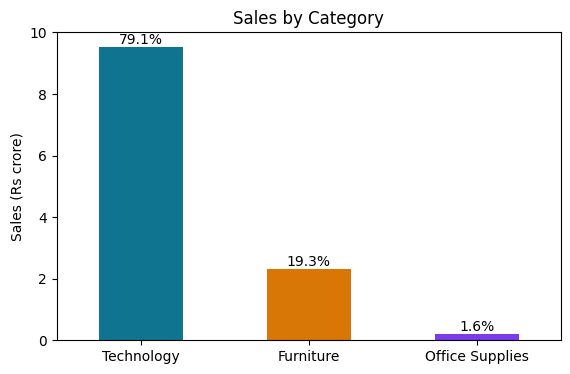

,Sales (Rs crore),Share_%
Category,,
Technology,9.53,79.1
Furniture,2.32,19.3
Office Supplies,0.19,1.6


In [ ]:
category = df.groupby("Category")["Sales"].sum().sort_values(ascending=False)

(category / 1e7).plot(kind="bar")
plt.title("Sales by Category")
plt.ylabel("Sales (Rs crore)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

# Share of each category in total sales (%)
share = (category / category.sum() * 100).round(1)
print(share)

Region
South    32379795.16
West     30843665.93
North    30707353.97
East     26526234.37
Name: Sales, dtype: float64


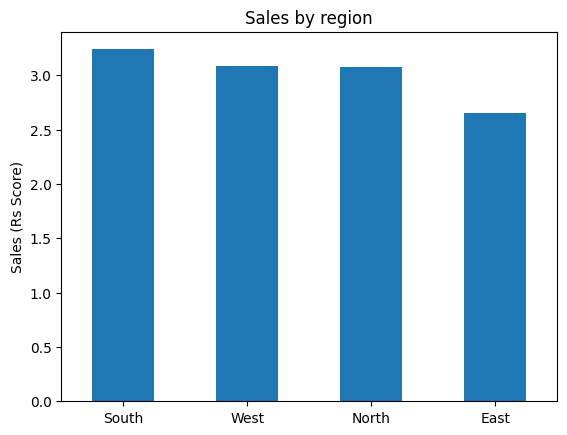

In [9]:
region=df.groupby("Region")["Sales"].sum().sort_values(ascending=False)
print(region)
(region/1e7).plot(kind="bar")
plt.title("Sales by region")
plt.ylabel("Sales (Rs Score)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

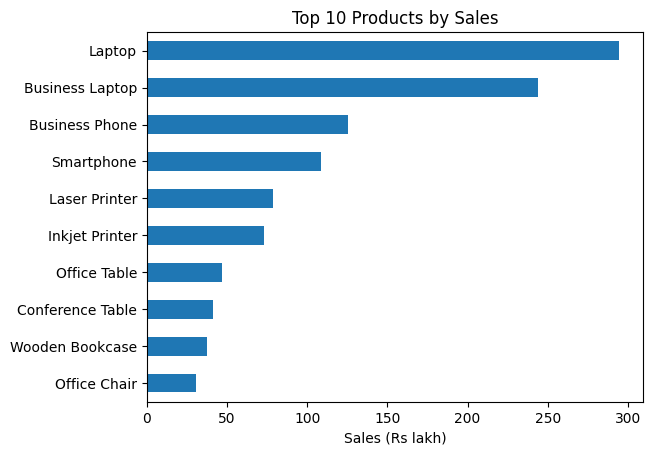

In [ ]:
product=df.groupby("Product_Name")["Sales"].sum()/1e5
top10=product.nlargest(10)
top10.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Sales")
plt.xlabel("Sales (Rs lakh)")
plt.ylabel("")
plt.show()


Total Profit (crore): 1.29
Profit margin %: 10.7


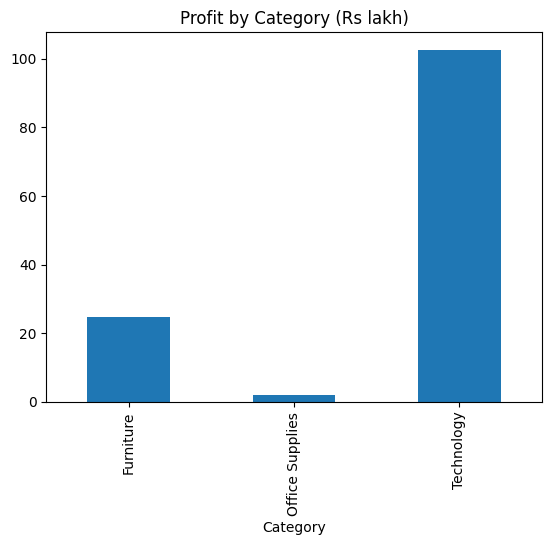

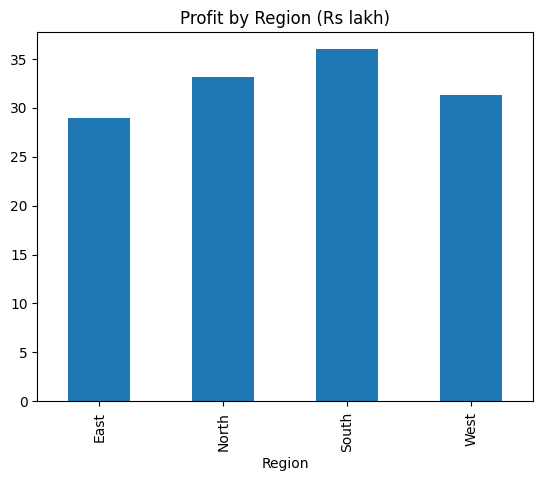

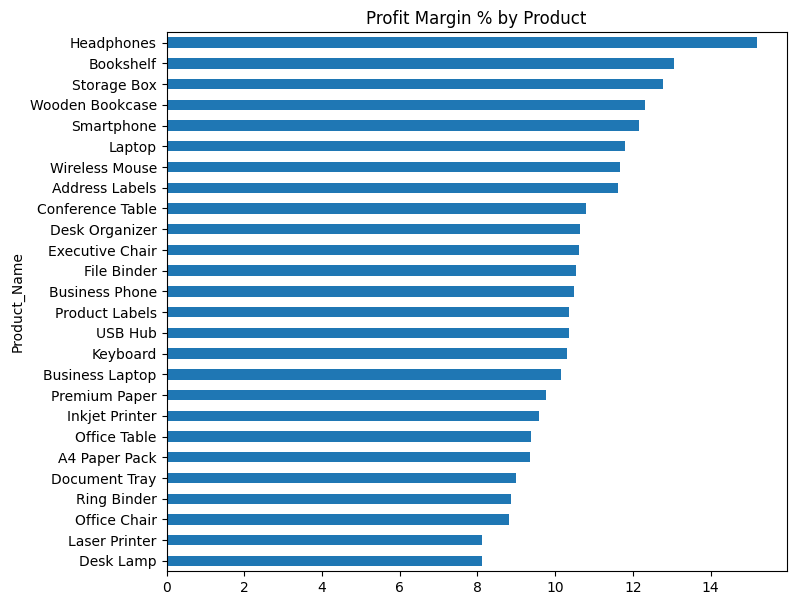

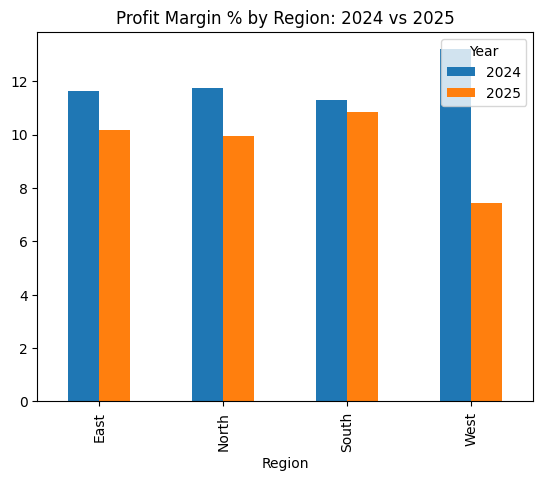

Year    2024  2025
Region            
East    11.6  10.2
North   11.7  10.0
South   11.3  10.8
West    13.2   7.4


In [17]:
# Total profit and margin
total_profit = df["Profit"].sum()
print("Total Profit (crore):", round(total_profit / 1e7, 2))
print("Profit margin %:", round(total_profit / df["Sales"].sum() * 100, 1))

# Profit by Category
(df.groupby("Category")["Profit"].sum() / 1e5).plot(kind="bar", title="Profit by Category (Rs lakh)")
plt.show()

# Profit by Region
(df.groupby("Region")["Profit"].sum() / 1e5).plot(kind="bar", title="Profit by Region (Rs lakh)")
plt.show()

# Profit margin % by Product
product_margin = df.groupby("Product_Name")["Profit"].sum() / df.groupby("Product_Name")["Sales"].sum() * 100
product_margin.sort_values().plot(kind="barh", figsize=(8, 7), title="Profit Margin % by Product")
plt.show()

# Profit margin % by Region, 2024 vs 2025
profit = df.groupby(["Region", "Year"])["Profit"].sum()
sales = df.groupby(["Region", "Year"])["Sales"].sum()
margin = (profit / sales * 100).unstack()
margin.plot(kind="bar", title="Profit Margin % by Region: 2024 vs 2025")
plt.show()
print(margin.round(1))

In [16]:
# True if the order lost money
df["Is_Loss"] = df["Profit"] < 0

# How many orders lost money
print("Loss orders:", df["Is_Loss"].sum(), "out of", len(df))

# % of loss orders in each region
print(df.groupby("Region")["Is_Loss"].mean() * 100)

# % of loss orders at each discount level
print(df.groupby("Discount_Level")["Is_Loss"].mean() * 100)

Loss orders: 669 out of 2965
Region
East     21.614227
North    22.293814
South    22.128852
West     24.193548
Name: Is_Loss, dtype: float64
Discount_Level
High Discount    22.081017
Low Discount     22.723610
No Discount      23.094688
Name: Is_Loss, dtype: float64


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("transformed_retail_sales.csv", parse_dates=["Order_Date"])

customer_sales = df.groupby("Customer_ID")["Sales"].sum().sort_values(ascending=False)

print(customer_sales.round(0).head(10))
print("Number of customers:", len(customer_sales))



Customer_ID
CUST-1001    7540283.0
CUST-1007    7384695.0
CUST-1010    7020738.0
CUST-1019    6875038.0
CUST-1016    6828655.0
CUST-1006    6596697.0
CUST-1020    6517525.0
CUST-1014    6468009.0
CUST-1012    6282236.0
CUST-1008    6120659.0
Name: Sales, dtype: float64
Number of customers: 20


In [11]:
customer_sales = df.groupby("Customer_ID")["Sales"].sum().sort_values(ascending=False)
print(customer_sales.round(0).head(10)) #top 10
print(customer_sales.round(0).head(20))



Customer_ID
CUST-1001    7540283.0
CUST-1007    7384695.0
CUST-1010    7020738.0
CUST-1019    6875038.0
CUST-1016    6828655.0
CUST-1006    6596697.0
CUST-1020    6517525.0
CUST-1014    6468009.0
CUST-1012    6282236.0
CUST-1008    6120659.0
Name: Sales, dtype: float64
Customer_ID
CUST-1001    7540283.0
CUST-1007    7384695.0
CUST-1010    7020738.0
CUST-1019    6875038.0
CUST-1016    6828655.0
CUST-1006    6596697.0
CUST-1020    6517525.0
CUST-1014    6468009.0
CUST-1012    6282236.0
CUST-1008    6120659.0
CUST-1003    5773524.0
CUST-1017    5551094.0
CUST-1011    5548191.0
CUST-1015    5480540.0
CUST-1013    5302548.0
CUST-1009    5171128.0
CUST-1002    5168222.0
CUST-1004    5130333.0
CUST-1005    4939652.0
CUST-1018    4330016.0
Name: Sales, dtype: float64


In [ ]:
customer_profit = df.groupby("Customer_ID")["Profit"].sum().sort_values(ascending=False)
top10_profit = customer_profit.head(10)
print("Top 10 share of profit:", top10_profit)

Top 10 share of profit: Customer_ID
CUST-1007    905688.85
CUST-1019    840323.09
CUST-1010    801445.66
CUST-1016    794729.58
CUST-1017    767881.00
CUST-1014    752261.04
CUST-1011    734690.47
CUST-1004    702379.18
CUST-1001    678436.09
CUST-1005    658949.30
Name: Profit, dtype: float64


In [ ]:
customer_sales=df.groupby("Customer_ID")["Sales"].sum()
average_spending=customer_sales.sum()/len(customer_sales)
print("Average spending per customer:",average_spending)

Average spending per customer: 6001489.148


In [ ]:
orders_per_customer = df.groupby("Customer_ID")["Order_ID"].nunique()
print("Customers with more than one order:", (orders_per_customer > 1).sum(), "out of", len(orders_per_customer))
print("Orders per customer: min", orders_per_customer.min(), ", max", orders_per_customer.max())

Customers with more than one order: 20 out of 20
Orders per customer: min 129 , max 172


In [17]:
yearly = df.groupby(["Customer_ID", "Year"])["Sales"].sum().unstack()
change = ((yearly[2025] / yearly[2024] - 1) * 100).round(1).sort_values()

print(change)


Customer_ID
CUST-1005   -44.0
CUST-1015   -41.4
CUST-1012   -40.7
CUST-1013   -40.5
CUST-1018   -35.6
CUST-1004   -29.8
CUST-1014   -23.5
CUST-1019   -23.0
CUST-1006    -5.8
CUST-1017    -5.5
CUST-1003    -3.6
CUST-1011    -0.2
CUST-1016    -0.1
CUST-1008     8.8
CUST-1010    17.8
CUST-1002    26.1
CUST-1007    32.0
CUST-1020    46.1
CUST-1001    59.9
CUST-1009    73.5
dtype: float64


In [20]:
customer_sales = df.groupby("Customer_ID")["Sales"].sum().sort_values(ascending=False)
contribution=(customer_sales/customer_sales.sum()*100).round(1)
print(contribution)


Customer_ID
CUST-1001    6.3
CUST-1007    6.2
CUST-1010    5.8
CUST-1019    5.7
CUST-1016    5.7
CUST-1006    5.5
CUST-1020    5.4
CUST-1014    5.4
CUST-1012    5.2
CUST-1008    5.1
CUST-1003    4.8
CUST-1017    4.6
CUST-1011    4.6
CUST-1015    4.6
CUST-1013    4.4
CUST-1009    4.3
CUST-1002    4.3
CUST-1004    4.3
CUST-1005    4.1
CUST-1018    3.6
Name: Sales, dtype: float64


In [21]:
known = df[df["Customer_Segment"] != "Unknown"]   # leave out the 12 orders with no customer ID
group = known.groupby("Customer_Segment")

print("Customers per segment:")
print(group["Customer_ID"].nunique())

print("\nSales (Rs lakh):")
print((group["Sales"].sum() / 1e5).round(1))

print("\nShare of total sales (%):")
print((group["Sales"].sum() / known["Sales"].sum() * 100).round(1))

print("\nProfit margin (%):")
print((group["Profit"].sum() / group["Sales"].sum() * 100).round(1))

Customers per segment:
Customer_Segment
High Value      7
Low Value       7
Medium Value    6
Name: Customer_ID, dtype: int64

Sales (Rs lakh):
Customer_Segment
High Value      487.6
Low Value       355.2
Medium Value    357.4
Name: Sales, dtype: float64

Share of total sales (%):
Customer_Segment
High Value      40.6
Low Value       29.6
Medium Value    29.8
Name: Sales, dtype: float64

Profit margin (%):
Customer_Segment
High Value      10.7
Low Value       10.5
Medium Value    11.0
dtype: float64


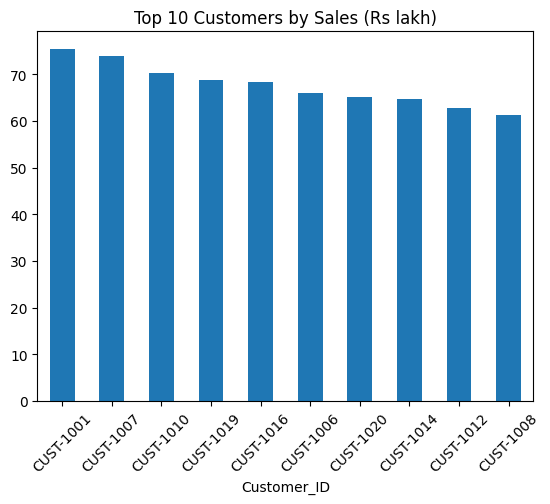

In [22]:
customer_sales = df.groupby("Customer_ID")["Sales"].sum().sort_values(ascending=False)

(customer_sales.head(10) / 1e5).plot(kind="bar", title="Top 10 Customers by Sales (Rs lakh)") # TOP 10 customers
plt.xticks(rotation=45)
plt.show()

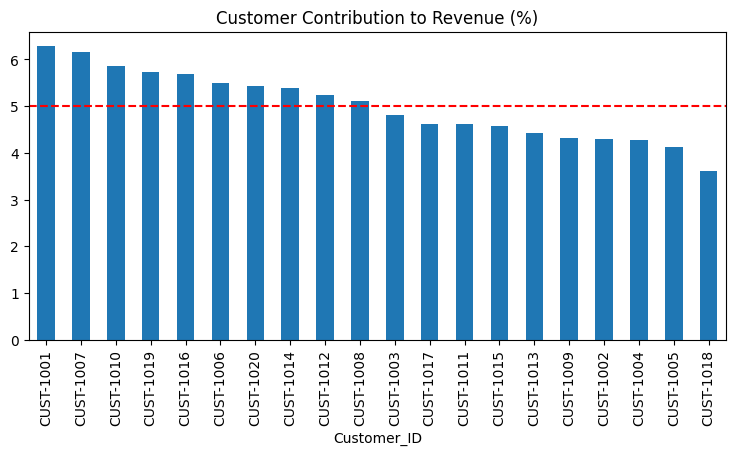

In [23]:
(customer_sales / customer_sales.sum() * 100).plot(kind="bar", title="Customer Contribution to Revenue (%)", figsize=(9, 4))
plt.axhline(5, color="red", linestyle="--")
plt.show()

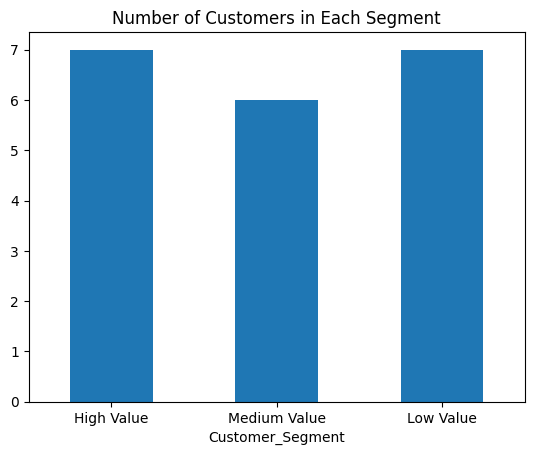

In [24]:
#number of customers in each segment
known = df[df["Customer_Segment"] != "Unknown"]
segment_customers = known.groupby("Customer_Segment")["Customer_ID"].nunique()[["High Value", "Medium Value", "Low Value"]]
segment_customers.plot(kind="bar", title="Number of Customers in Each Segment")
plt.xticks(rotation=0)
plt.show()

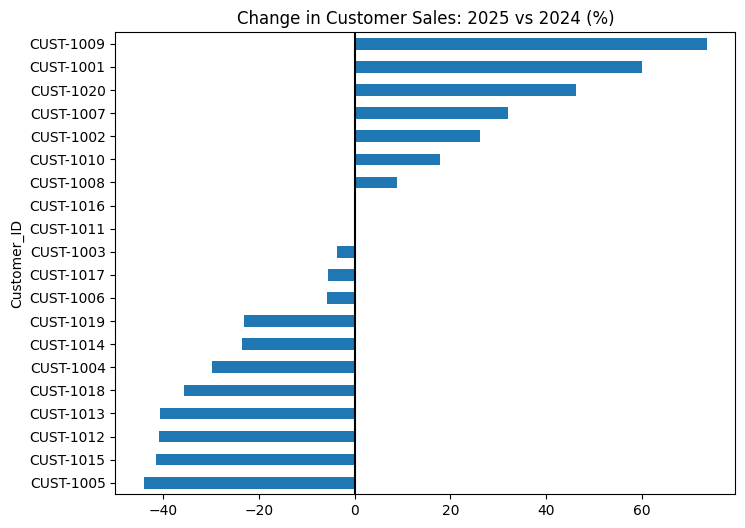

In [25]:
# (replaces repeat vs one-time): change in each customer's sales, 2025 vs 2024
yearly = df.groupby(["Customer_ID", "Year"])["Sales"].sum().unstack()
change = ((yearly[2025] / yearly[2024] - 1) * 100).sort_values()
change.plot(kind="barh", title="Change in Customer Sales: 2025 vs 2024 (%)", figsize=(8, 6))
plt.axvline(0, color="black")
plt.show()